# Phase 1 — METR-LA: get the data and understand it

**Goal:** know the data well enough to justify every later modelling choice. This notebook produces the five EDA figures the playbook asks for (plus a worked example) and writes the findings to `results/phase1_findings.json`.

**Rules followed here**
- No analysis logic lives in this notebook; it calls `src/analysis/eda.py` and `src/viz/eda_plots.py`.
- `0 mph` = sensor down, **not** a traffic jam. It is masked (NaN) in every statistic below.
- Anything that could steer modelling (profiles, peak windows, propagation lags) uses the **training period only** (first 70% of timestamps). The test period stays unseen until Phase 6. Missingness is a data-quality check, so it covers the full period.

In [1]:
import json, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data.load import load_all, load_distances
from src.analysis import eda
from src.viz import eda_plots as P, style
style.apply()
pd.set_option("display.precision", 3)

## 0 · Load and verify
The speed columns must be in exactly the same order as the adjacency rows; `load_all()` raises if not. A GNN trained on a scrambled graph still trains, it just learns nonsense, so this is checked first.

In [2]:
speed, graph, loc = load_all()
train = eda.train_slice(speed)
step = speed.index.to_series().diff().value_counts()
print(f"speed matrix      : {speed.shape[0]:,} timestamps x {speed.shape[1]} sensors")
print(f"period            : {speed.index.min()} -> {speed.index.max()}  ({speed.index.normalize().nunique()} days)")
print(f"sampling          : {dict(step)} (no gaps in the clock)")
print(f"train period (70%): {train.index.min()} -> {train.index.max()}")
print(f"adjacency         : {graph.adj.shape}, {(graph.adj > 0).sum()} non-zeros incl. self-loops, symmetric = {np.allclose(graph.adj, graph.adj.T)}")
print(f"column order == graph order: {list(speed.columns) == graph.sensor_ids}")
print(f"locations for every sensor : {loc.notna().all().all()}")
speed.iloc[:3, :6]

speed matrix      : 34,272 timestamps x 207 sensors
period            : 2012-03-01 00:00:00 -> 2012-06-27 23:55:00  (119 days)
sampling          : {Timedelta('0 days 00:05:00'): np.int64(34271)} (no gaps in the clock)
train period (70%): 2012-03-01 00:00:00 -> 2012-05-23 07:05:00
adjacency         : (207, 207), 1722 non-zeros incl. self-loops, symmetric = False
column order == graph order: True
locations for every sensor : True


sensor_id,773869,767541,767542,717447,717446,717445
timestamp,,,,,,
2012-03-01 00:00:00,64.375,67.625,67.125,61.500,66.875,68.750
2012-03-01 00:05:00,62.667,68.556,65.444,62.444,64.444,68.111
2012-03-01 00:10:00,64.000,63.750,60.000,59.000,66.500,66.250


## 1 · Missingness
In METR-LA a value of `0` means the loop detector reported nothing. We split outages into **whole-network** outages (every sensor 0 at the same timestamp: a logging/system failure) and **single-sensor** outages.

findfont: Failed to find font weight semibold for Helvetica Neue, now using 700.


zeros overall                 : 8.11% of readings
  whole-network outages       : 2,148 timestamps -> 6.27 points
  single-sensor outages       : 1.84 points
longest whole-network outage  : 381 steps = 31.8 h
sensors with > 20% zeros      : 1
worst sensors (% zeros):
sensor_id
718076    20.1
716939    18.9
760987    16.1
716955    15.7
769418    15.6
769405    15.6
717481    15.1
717510    15.0
717513    14.1
717576    13.6


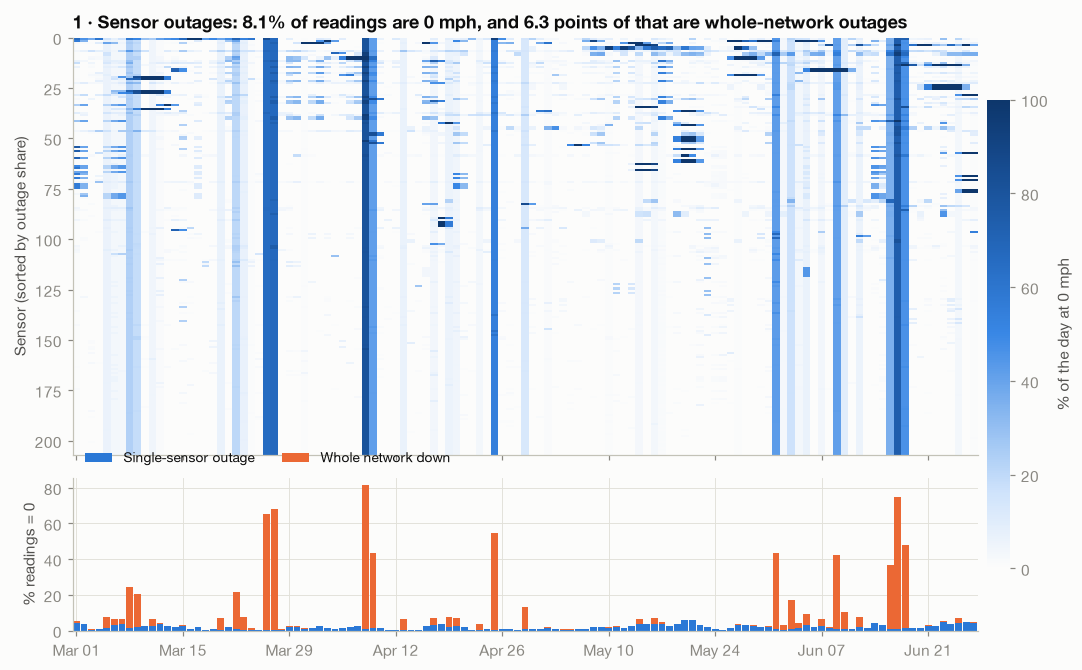

In [3]:
miss, by_day = eda.missingness(speed)
print(f"zeros overall                 : {miss.zero_pct:.2f}% of readings")
print(f"  whole-network outages       : {miss.network_outage_steps:,} timestamps -> {miss.network_outage_pct:.2f} points")
print(f"  single-sensor outages       : {miss.sensor_outage_pct:.2f} points")
print(f"longest whole-network outage  : {miss.longest_network_outage_steps} steps = {miss.longest_network_outage_steps*5/60:.1f} h")
print(f"sensors with > 20% zeros      : {miss.sensors_over_20pct}")
print("worst sensors (% zeros):"); print(miss.worst_sensors.round(1).to_string())
fig = P.plot_missingness(speed, by_day, miss); P.save(fig, "fig01_missingness.png"); plt.show()

**Takeaway.** About three quarters of the zeros are whole-network outages, which carry no traffic information at all. If they were treated as real 0 mph readings, a model would learn that the whole city occasionally stops dead. Phase 2 masks them in the loss and in every metric, and gives the model a mask channel so it knows when an input was imputed.

## 2 · Daily profile
Network-mean speed per 5-minute slot (train period, outages masked). Peak windows are found from the data: contiguous spans where the weekday mean falls below 90% of free flow (95th percentile of the profile).

peak 07:05-10:45  lowest weekday mean 49.0 mph
peak 14:30-19:15  lowest weekday mean 45.7 mph
weekday free flow (95th pct of profile): 63.2 mph;  weekend min: 56.7 mph


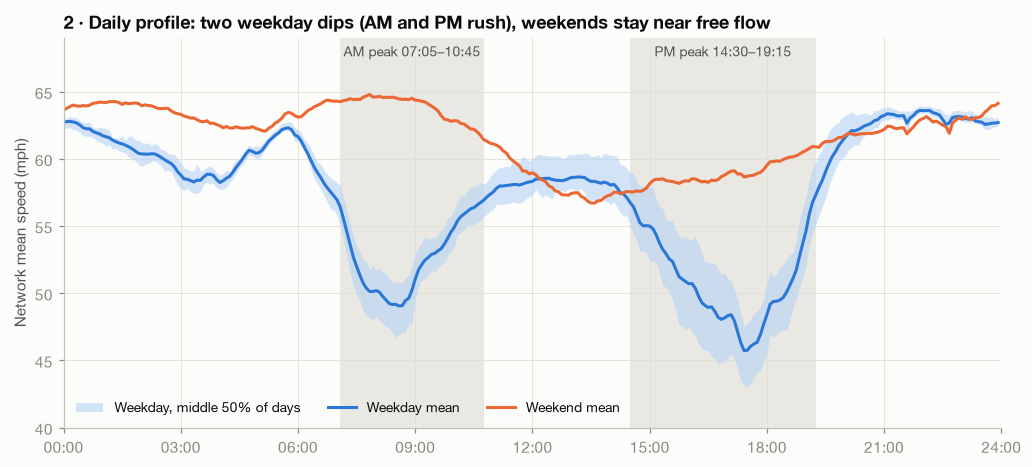

In [4]:
profile = eda.daily_profile(train)
peaks = eda.peak_windows(profile.weekday)
for a, b, v in peaks:
    print(f"peak {P._hhmm(a)}-{P._hhmm(b)}  lowest weekday mean {v:.1f} mph")
print(f"weekday free flow (95th pct of profile): {profile.weekday.quantile(.95):.1f} mph;  weekend min: {profile.weekend.min():.1f} mph")
fig = P.plot_daily_profile(profile, peaks); P.save(fig, "fig02_daily_profile.png"); plt.show()

**Takeaway.** Two clear weekday dips. The PM dip is deeper and longer than the AM dip. The data-driven windows enclose the brief's fixed definition (AM 07:00–09:59, PM 16:00–19:59), which Phase 6 uses for the peak vs off-peak split, so that definition is supported by the data. Weekends barely dip, so day-of-week features matter.

## 3 · Speed distribution

{'median': 63.22, 'pct_ge_60': 66.36, 'pct_lt_40': 10.5, 'pct_lt_20': 2.75}


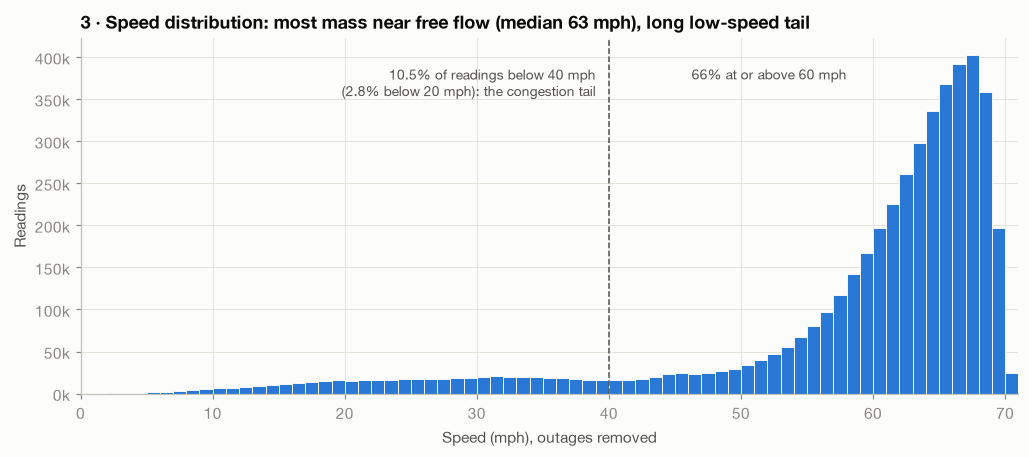

In [5]:
dist = eda.speed_distribution(train)
print({k: round(v, 2) for k, v in dist.items() if k != "values"})
fig = P.plot_distribution(dist); P.save(fig, "fig03_speed_distribution.png"); plt.show()

**Takeaway.** The distribution is heavily skewed: most readings sit at 60–70 mph, and congestion is the rare low-speed tail. Two consequences: (1) average MAE is dominated by easy free-flow periods, so Phase 6 must also report peak hours and congestion onsets separately; (2) MAPE is unstable at low speeds, which is one more reason to mask zeros.

## 4 · The sensor graph
`adj_mx[i, j] > 0` means there is a short **driving** path from sensor *i* to sensor *j* (Gaussian kernel of road distance, threshold 0.1), so *i* is upstream of *j*. The matrix is **directed**.

{'nodes': 207, 'edges': 1515, 'reciprocal_edge_pct': 26.67, 'mean_degree': 7.32, 'isolated_nodes': 1, 'weak_components': 2, 'largest_weak_component': 206}
in-degree  range: 0 - 17  | out-degree range: 0 - 18


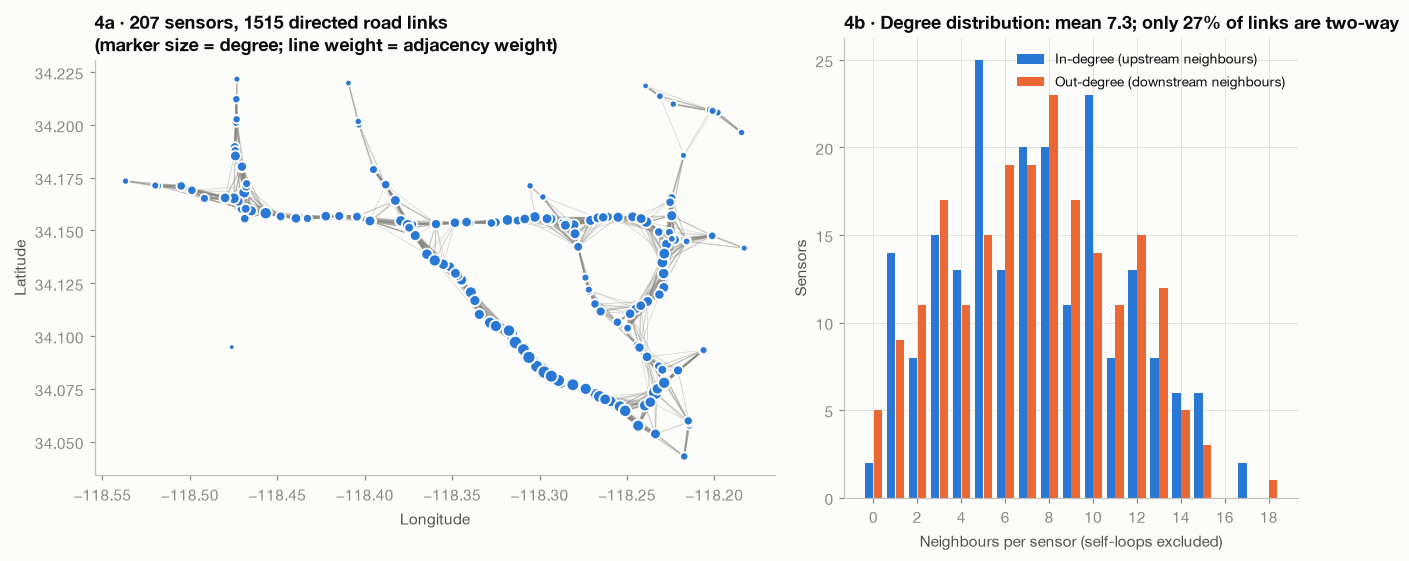

interactive map -> docs/figures/fig04_sensor_graph_map.html


In [6]:
G = eda.build_digraph(graph.adj, graph.sensor_ids)
gs = eda.graph_stats(G)
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in gs.items() if k not in ("in_degree", "out_degree")})
print("in-degree  range:", gs["in_degree"].min(), "-", gs["in_degree"].max(), " | out-degree range:", gs["out_degree"].min(), "-", gs["out_degree"].max())
fig = P.plot_graph(G, loc, gs); P.save(fig, "fig04_sensor_graph.png"); plt.show()
P.graph_map_html(G, loc, graph.sensor_ids, P.FIG_DIR / "fig04_sensor_graph_map.html")
print("interactive map -> docs/figures/fig04_sensor_graph_map.html")

**Takeaway.** Only about a quarter of links are two-way, so direction carries real information: upstream and downstream neighbours tell different stories. Phase 2 keeps the matrix directed, and Phase 5 tests undirected vs directed as an ablation. One sensor has no neighbours within the kernel threshold, so a GNN can only use its own history (watch it in the per-sensor error map in Phase 7).

## 5 · Spatial correlation: does congestion travel along the road?
This is the figure that motivates the whole project.

**Method.** Raw speeds share the same daily rhythm, so every pair of sensors correlates at every lag. That is not useful. We subtract each sensor's (weekday/weekend × time-of-day) mean, which leaves the day-specific disturbances. For every directed link *u → d* we compute `corr(u[t−k], d[t])` for k = −60…+60 min.
- best lag **> 0**: the upstream sensor moves first (the disturbance travels *with* traffic)
- best lag **< 0**: the downstream sensor moves first (a congestion **shockwave** travelling *backwards*, against traffic, which is what queues do)

Links whose peak correlation is below 0.3 are reported as *weak* and left out of the lag statistics.

{'edges': 1515, 'weak_edge_pct': 62.2, 'clear_edges': 499, 'same_step_pct': 60.5, 'downstream_first': 156, 'upstream_first': 41, 'median_lag_min': 10.0, 'shockwave_kmh': 16.0}


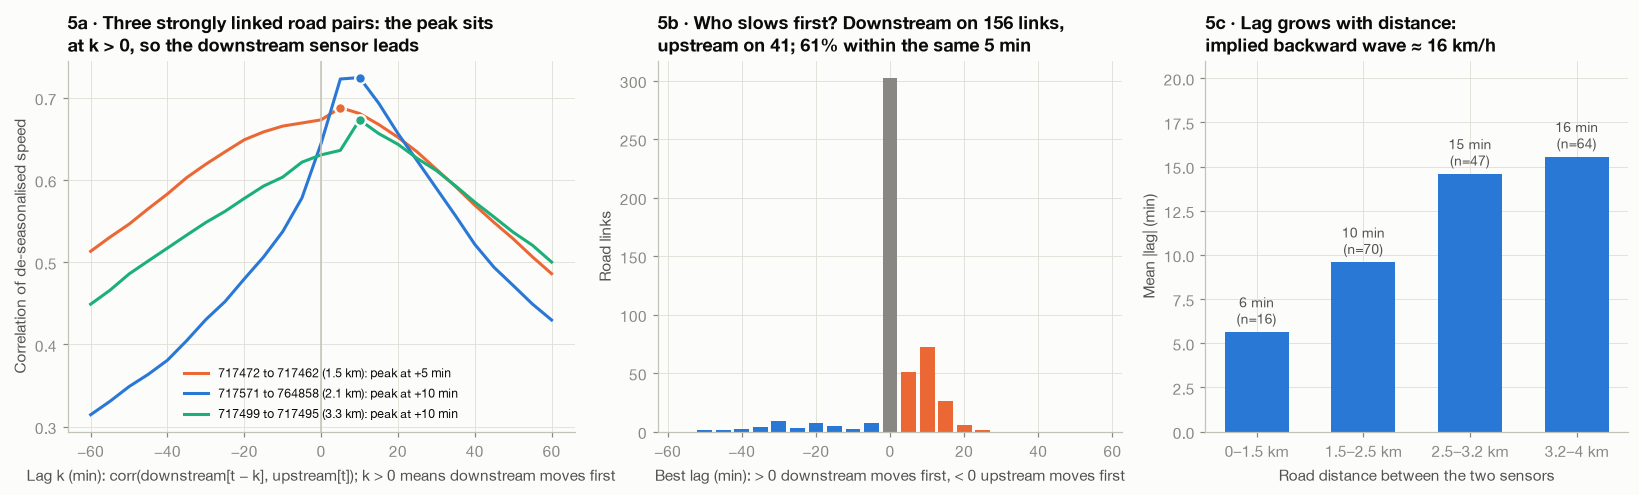

In [7]:
resid = eda.deseasonalised(train)
tab, curves = eda.edge_lag_table(resid, G, max_lag=12, distances=load_distances(), sensor_ids=graph.sensor_ids)
prop = eda.propagation_summary(tab)
print({k: (round(v, 1) if isinstance(v, float) else v) for k, v in prop.items()})
link, t_down, t_up = eda.pick_example(tab, train)
# 5a shows the worked-example link plus the two most strongly coupled other downstream-first links
others = tab[tab.clear & (tab.best_lag <= -2) & (tab.index != link.name)].sort_values("corr_peak", ascending=False)
links = [link.name] + list(others.index[:2])
fig = P.plot_propagation(tab, curves, links, graph.sensor_ids, prop); P.save(fig, "fig05_spatial_propagation.png"); plt.show()

example link: 717472 -> 717462, 1.51 km, best lag -5 min, corr 0.69 (vs 0.67 at lag 0)


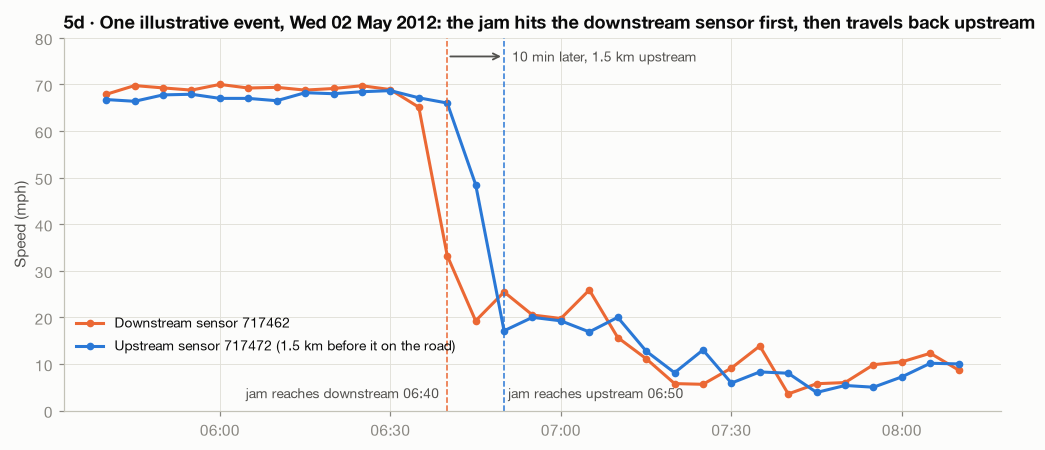

In [8]:
print(f"example link: {graph.sensor_ids[int(link.up)]} -> {graph.sensor_ids[int(link.down)]}, {link.dist_km:.2f} km, "
      f"best lag {int(link.best_lag)*5} min, corr {link.corr_peak:.2f} (vs {link.corr_lag0:.2f} at lag 0)")
fig = P.plot_propagation_example(train, int(link.up), int(link.down), t_down, t_up, graph.sensor_ids, link.dist_km)
P.save(fig, "fig05d_propagation_example.png"); plt.show()

**Takeaways (these feed the Phase 4 gap statement and the Phase 5 model design):**
1. **Congestion moves through the graph.** On linked sensors that move together, most co-move within the same 5-minute step. Where there is a lag, the downstream sensor usually slows first and the upstream one follows minutes later. That is the queue growing backwards. A per-sensor model sees this only *after* the jam arrives; a graph model can see it coming from the neighbour.
2. **The lag is physical.** It grows with road distance, and the implied backward wave speed is close to the textbook 15–20 km/h for traffic shockwaves. This is a sanity check that the graph direction and the masking are right.
3. **The fixed graph is noisy.** Most distance-based links barely co-move (e.g. crossing freeways or opposite carriageways that are close by road). This argues for **attention** (GAT), which can learn to down-weight useless neighbours, over a fixed-weight GCN. It is also why a learned adjacency (Graph WaveNet) is a good Phase 9 ablation.
4. **The playbook's example is the less common direction.** The playbook's worked example has the upstream sensor slowing first. In this data, downstream-first is about 4× more common among lagged links. Either way, the information sits at a neighbour, which is the point.

## Findings → `results/phase1_findings.json`

In [9]:
findings = {
    "data": {"timestamps": int(speed.shape[0]), "sensors": int(speed.shape[1]),
             "start": str(speed.index.min()), "end": str(speed.index.max()),
             "train_end_70pct": str(train.index.max()), "column_order_matches_graph": True},
    "missingness": {"zero_pct": round(miss.zero_pct, 2), "network_outage_pct": round(miss.network_outage_pct, 2),
                    "sensor_outage_pct": round(miss.sensor_outage_pct, 2),
                    "network_outage_timestamps": miss.network_outage_steps,
                    "longest_network_outage_hours": round(miss.longest_network_outage_steps * 5 / 60, 1),
                    "worst_sensor": {miss.worst_sensors.index[0]: round(float(miss.worst_sensors.iloc[0]), 1)}},
    "daily_profile": {"peak_windows": [{"start": P._hhmm(a), "end": P._hhmm(b), "min_mph": round(v, 1)} for a, b, v in peaks],
                      "weekday_free_flow_mph": round(float(profile.weekday.quantile(.95)), 1),
                      "weekend_min_mph": round(float(profile.weekend.min()), 1)},
    "distribution": {k: round(v, 2) for k, v in dist.items() if k != "values"},
    "graph": {k: (round(v, 2) if isinstance(v, float) else v) for k, v in gs.items() if k not in ("in_degree", "out_degree")},
    "propagation": {k: (round(v, 1) if isinstance(v, float) else v) for k, v in prop.items()},
}
out = ROOT / "results" / "phase1_findings.json"; out.parent.mkdir(exist_ok=True)
out.write_text(json.dumps(findings, indent=2)); print(json.dumps(findings, indent=2))

{
  "data": {
    "timestamps": 34272,
    "sensors": 207,
    "start": "2012-03-01 00:00:00",
    "end": "2012-06-27 23:55:00",
    "train_end_70pct": "2012-05-23 07:05:00",
    "column_order_matches_graph": true
  },
  "missingness": {
    "zero_pct": 8.11,
    "network_outage_pct": 6.27,
    "sensor_outage_pct": 1.84,
    "network_outage_timestamps": 2148,
    "longest_network_outage_hours": 31.8,
    "worst_sensor": {
      "718076": 20.1
    }
  },
  "daily_profile": {
    "peak_windows": [
      {
        "start": "07:05",
        "end": "10:45",
        "min_mph": 49.0
      },
      {
        "start": "14:30",
        "end": "19:15",
        "min_mph": 45.7
      }
    ],
    "weekday_free_flow_mph": 63.2,
    "weekend_min_mph": 56.7
  },
  "distribution": {
    "median": 63.22,
    "pct_ge_60": 66.36,
    "pct_lt_40": 10.5,
    "pct_lt_20": 2.75
  },
  "graph": {
    "nodes": 207,
    "edges": 1515,
    "reciprocal_edge_pct": 26.67,
    "mean_degree": 7.32,
    "isolated_nodes